In [1]:
import pandas as pd

product_sales = pd.read_csv(
    r"D:\Portfolio\retail-online-analysis\data\product_sales.csv",
    dtype={'InvoiceNo': 'string'}
)

product_sales['InvoiceDate'] = pd.to_datetime(product_sales['InvoiceDate'])
product_sales['CustomerID'] = product_sales['CustomerID'].astype('Int64')

product_sales['Revenue'] = product_sales['Quantity'] * product_sales['UnitPrice']

In [2]:
# Best selling-products for each month
# 1. Extract month and year from InvoiceDate
product_sales['YearMonth'] = product_sales['InvoiceDate'].dt.to_period('M')

In [3]:
# 2. Group by YearMonth and Description, sum Quantity
product_sales_grouped = product_sales.groupby(['YearMonth', 'Description']).agg({'Quantity': 'sum'}).reset_index()

print("\nGrouped Product Sales DataFrame:")
print(product_sales_grouped.head())


Grouped Product Sales DataFrame:
  YearMonth                       Description  Quantity
0   2010-12     4 PURPLE FLOCK DINNER CANDLES        16
1   2010-12        OVAL WALL MIRROR DIAMANTE         22
2   2010-12   SET 2 TEA TOWELS I LOVE LONDON        306
3   2010-12             *Boombox Ipod Classic         1
4   2010-12           *USB Office Mirror Ball         2


In [4]:
# 3. Sort by YearMonth and Quantity in descending order
product_sales_grouped = (
    product_sales.groupby(['YearMonth', 'Description'])
    .agg(
        Total_Quantity=('Quantity', 'sum'),
        Total_Revenue=('Revenue', 'sum')
    )
    .reset_index()
)

print("\nSorted Grouped Product Sales DataFrame:")
print(product_sales_grouped.head())


Sorted Grouped Product Sales DataFrame:
  YearMonth                       Description  Total_Quantity  Total_Revenue
0   2010-12     4 PURPLE FLOCK DINNER CANDLES              16          45.82
1   2010-12        OVAL WALL MIRROR DIAMANTE               22         283.03
2   2010-12   SET 2 TEA TOWELS I LOVE LONDON              306        1006.94
3   2010-12             *Boombox Ipod Classic               1          16.98
4   2010-12           *USB Office Mirror Ball               2          16.94


In [5]:
# 4. Drop duplicates to keep only the best-selling product for each month
best_selling_products_monthly = (
    product_sales_grouped
    .sort_values(
        ['YearMonth', 'Total_Quantity'],
        ascending=[True, False]
    )
    .drop_duplicates(subset=['YearMonth'], keep='first')
    .reset_index(drop=True)
)

print("\nBest Selling Products for Each Month:")
print(best_selling_products_monthly)


Best Selling Products for Each Month:
   YearMonth                        Description  Total_Quantity  Total_Revenue
0    2010-12  WORLD WAR 2 GLIDERS ASSTD DESIGNS            5195        1174.13
1    2011-01     MEDIUM CERAMIC TOP STORAGE JAR           74215       77183.60
2    2011-02              EMPIRE DESIGN ROSETTE            3986        3302.92
3    2011-03            JUMBO BAG RED RETROSPOT            5280       10118.38
4    2011-04  WORLD WAR 2 GLIDERS ASSTD DESIGNS           10239        2290.89
5    2011-05               SMALL POPCORN HOLDER            6841        5144.83
6    2011-06            JUMBO BAG RED RETROSPOT            3681        7247.98
7    2011-07  WORLD WAR 2 GLIDERS ASSTD DESIGNS            3762        1049.94
8    2011-08      ASSORTED COLOUR BIRD ORNAMENT            6545        9868.73
9    2011-09            JUMBO BAG RED RETROSPOT            4399        8880.17
10   2011-10  WORLD WAR 2 GLIDERS ASSTD DESIGNS            8084        1929.92
11   2011-11 

In [6]:
# 5. Put the data in a DataFrame
best_selling_products_monthly_df = best_selling_products_monthly.copy()
print("\nBest Selling Products for Each Month DataFrame:")
print(best_selling_products_monthly_df)


Best Selling Products for Each Month DataFrame:
   YearMonth                        Description  Total_Quantity  Total_Revenue
0    2010-12  WORLD WAR 2 GLIDERS ASSTD DESIGNS            5195        1174.13
1    2011-01     MEDIUM CERAMIC TOP STORAGE JAR           74215       77183.60
2    2011-02              EMPIRE DESIGN ROSETTE            3986        3302.92
3    2011-03            JUMBO BAG RED RETROSPOT            5280       10118.38
4    2011-04  WORLD WAR 2 GLIDERS ASSTD DESIGNS           10239        2290.89
5    2011-05               SMALL POPCORN HOLDER            6841        5144.83
6    2011-06            JUMBO BAG RED RETROSPOT            3681        7247.98
7    2011-07  WORLD WAR 2 GLIDERS ASSTD DESIGNS            3762        1049.94
8    2011-08      ASSORTED COLOUR BIRD ORNAMENT            6545        9868.73
9    2011-09            JUMBO BAG RED RETROSPOT            4399        8880.17
10   2011-10  WORLD WAR 2 GLIDERS ASSTD DESIGNS            8084        1929.92
11 

In [7]:
# 6. Combine columns
best_selling_products_monthly_df['Month_Product'] = (
    best_selling_products_monthly_df['YearMonth'].astype(str)
    + ' | '
    + best_selling_products_monthly_df['Description']
)

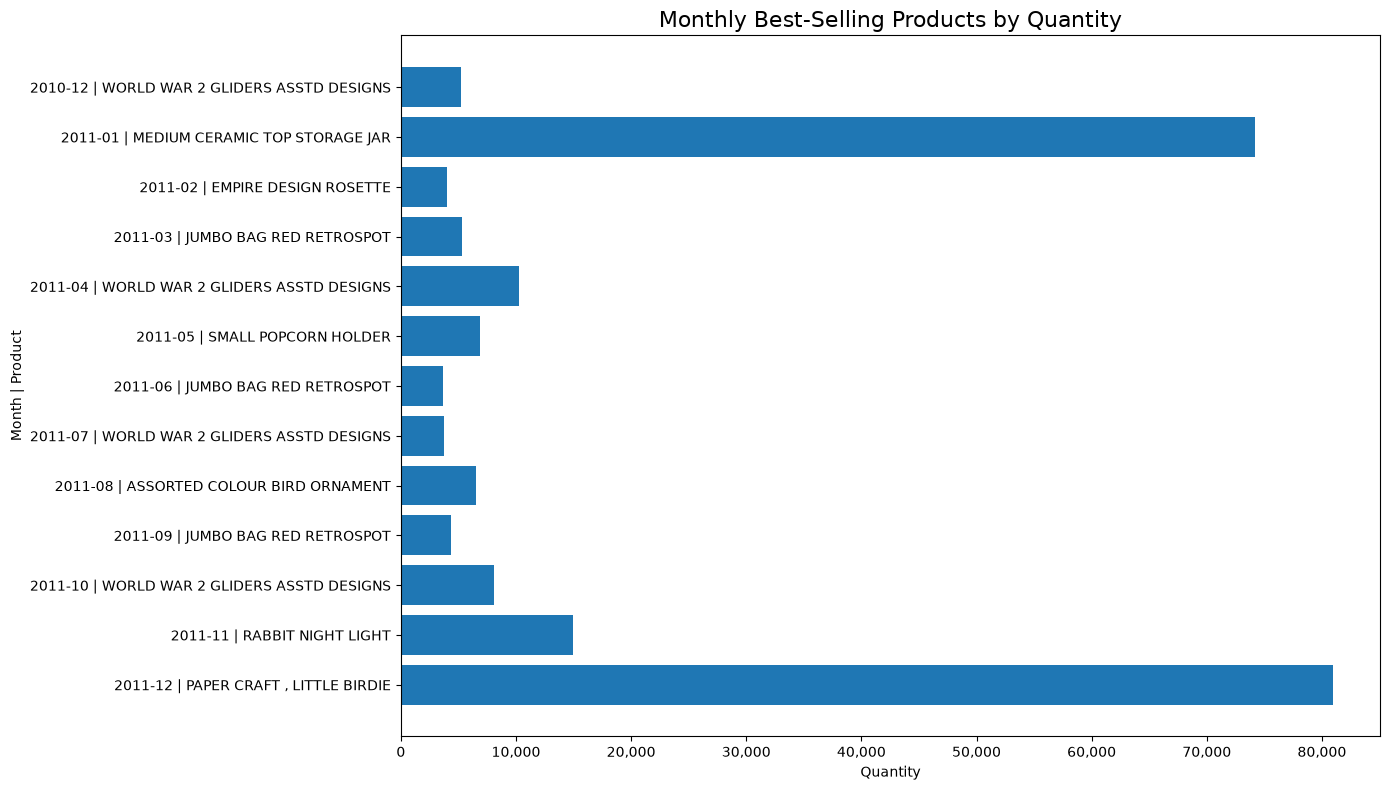

In [8]:
# 6. Visualize the best-selling products for each month with a horizontal bar chart
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(14, 8))

plt.barh(
    best_selling_products_monthly_df['Month_Product'],
    best_selling_products_monthly_df['Total_Quantity']
)

plt.title('Monthly Best-Selling Products by Quantity', fontsize=16)
plt.xlabel('Quantity')
plt.ylabel('Month | Product')

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()

In [9]:
# 7. Analyse products with the highest revenue for each month
top_revenue_products_monthly = (
    product_sales_grouped
    .sort_values(
        ['YearMonth', 'Total_Revenue'],
        ascending=[True, False]
    )
    .drop_duplicates(
        subset=['YearMonth'],
        keep='first'
    )
    .reset_index(drop=True)
)

print("\nTop Revenue Products for Each Month:")
print(top_revenue_products_monthly)


Top Revenue Products for Each Month:
   YearMonth                          Description  Total_Quantity  \
0    2010-12             REGENCY CAKESTAND 3 TIER            2077   
1    2011-01       MEDIUM CERAMIC TOP STORAGE JAR           74215   
2    2011-02             REGENCY CAKESTAND 3 TIER             901   
3    2011-03             REGENCY CAKESTAND 3 TIER            1452   
4    2011-04             REGENCY CAKESTAND 3 TIER            1195   
5    2011-05                        PARTY BUNTING            3555   
6    2011-06       PICNIC BASKET WICKER 60 PIECES              61   
7    2011-07                        PARTY BUNTING            2758   
8    2011-08              JUMBO BAG RED RETROSPOT            5402   
9    2011-09  SET OF TEA COFFEE SUGAR TINS PANTRY            2071   
10   2011-10             REGENCY CAKESTAND 3 TIER            1081   
11   2011-11                   RABBIT NIGHT LIGHT           14913   
12   2011-12          PAPER CRAFT , LITTLE BIRDIE           80995

In [10]:
# 8. Put the data in a DataFrame
top_revenue_products_monthly_df = top_revenue_products_monthly.copy()
print("\nTop Revenue Products for Each Month DataFrame:")
print(top_revenue_products_monthly_df)


Top Revenue Products for Each Month DataFrame:
   YearMonth                          Description  Total_Quantity  \
0    2010-12             REGENCY CAKESTAND 3 TIER            2077   
1    2011-01       MEDIUM CERAMIC TOP STORAGE JAR           74215   
2    2011-02             REGENCY CAKESTAND 3 TIER             901   
3    2011-03             REGENCY CAKESTAND 3 TIER            1452   
4    2011-04             REGENCY CAKESTAND 3 TIER            1195   
5    2011-05                        PARTY BUNTING            3555   
6    2011-06       PICNIC BASKET WICKER 60 PIECES              61   
7    2011-07                        PARTY BUNTING            2758   
8    2011-08              JUMBO BAG RED RETROSPOT            5402   
9    2011-09  SET OF TEA COFFEE SUGAR TINS PANTRY            2071   
10   2011-10             REGENCY CAKESTAND 3 TIER            1081   
11   2011-11                   RABBIT NIGHT LIGHT           14913   
12   2011-12          PAPER CRAFT , LITTLE BIRDIE      

In [11]:
# 9. Combine columns
top_revenue_products_monthly_df['Month_Product'] = (
    top_revenue_products_monthly_df['YearMonth'].astype(str)
    + ' | '
    + top_revenue_products_monthly_df['Description']
)

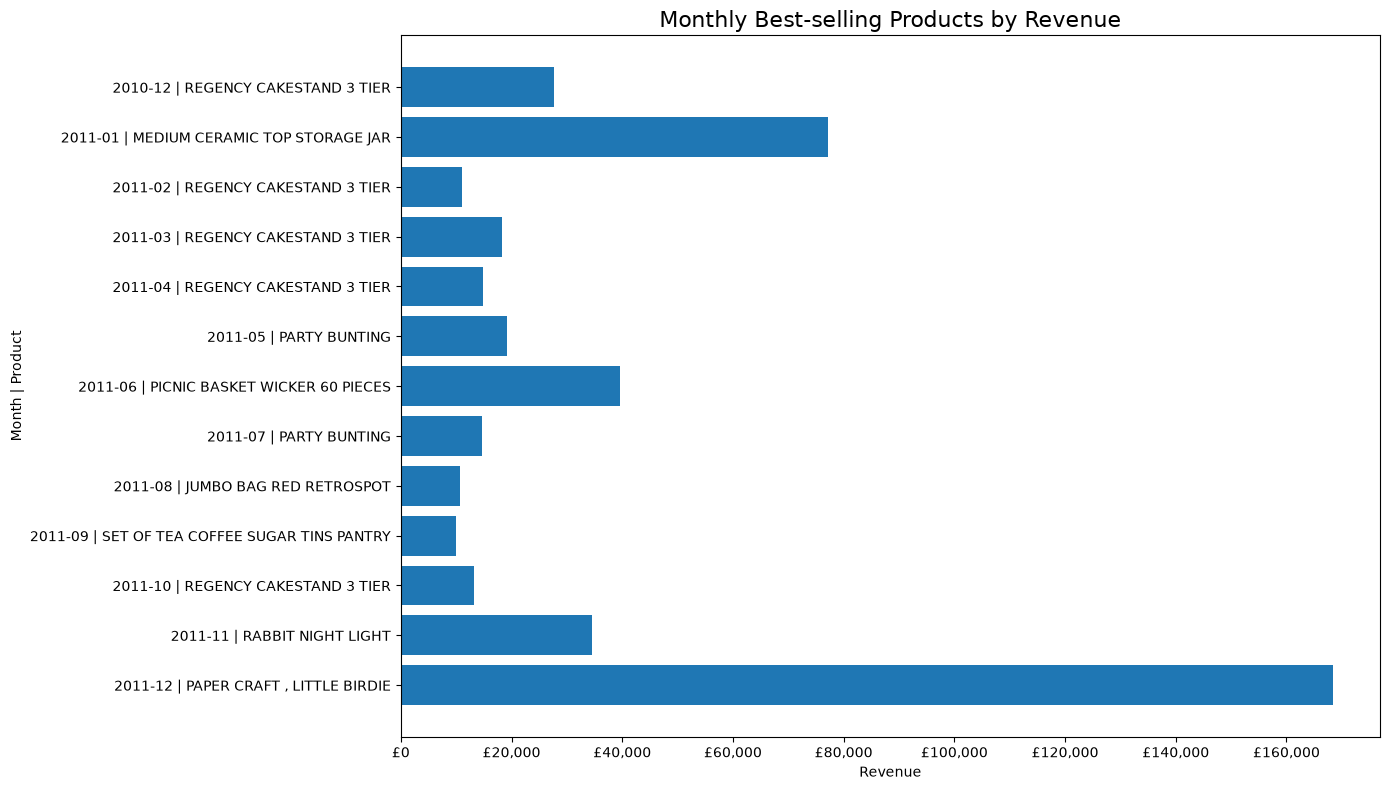

In [12]:
# 10. Visualize the top revenue products for each month with a horizontal bar chart
plt.figure(figsize=(14, 8))

plt.barh(
    top_revenue_products_monthly_df['Month_Product'],
    top_revenue_products_monthly_df['Total_Revenue']
)

plt.title('Monthly Best-selling Products by Revenue', fontsize=16)
plt.xlabel('Revenue')
plt.ylabel('Month | Product')

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()

# Summary

This notebook analyzes monthly product performance using product_sales.csv, focusing on total revenue and quantity sold.

| YearMonth | Description | Total_Quantity | Total_Revenue |
|-----------|-------------|---------------:|--------------:|
| 2010-12 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 5,195 | 1,174.13 |
| 2011-01 | MEDIUM CERAMIC TOP STORAGE JAR | 74,215 | 77,183.60 |
| 2011-02 | EMPIRE DESIGN ROSETTE | 3,986 | 3,302.92 |
| 2011-03 | JUMBO BAG RED RETROSPOT | 5,280 | 10,118.38 |
| 2011-04 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 10,239 | 2,290.89 |
| 2011-05 | SMALL POPCORN HOLDER | 6,841 | 5,144.83 |
| 2011-06 | JUMBO BAG RED RETROSPOT | 3,681 | 7,247.98 |
| 2011-07 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 3,762 | 1,049.94 |
| 2011-08 | ASSORTED COLOUR BIRD ORNAMENT | 6,545 | 9,868.73 |
| 2011-09 | JUMBO BAG RED RETROSPOT | 4,399 | 8,880.17 |
| 2011-10 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 8,084 | 1,929.92 |
| 2011-11 | RABBIT NIGHT LIGHT | 14,913 | 34,478.40 |
| 2011-12 | PAPER CRAFT , LITTLE BIRDIE | 80,995 | 168,469.60 |

Across the thirteen months, PAPER CRAFT , LITTLE BIRDIE recorded both the highest monthly product revenue (£168,469.60) and the highest monthly quantity sold (80,995 units) in December 2011.